# Chapitre 5 - Cours 4 : réplication sans leader et quorums

Leader unique ou multi-leader, un leader décide de l'ordre des écritures et les suiveurs
l'appliquent. Certains systèmes abandonnent purement et simplement la notion de leader :
n'importe quelle réplique accepte les écritures des clients. Ce style, présent dans les
tout premiers systèmes répliqués, est redevenu à la mode avec Dynamo, le système interne
d'Amazon (2007), dont s'inspirent Riak, Cassandra et Voldemort (d'où le nom de bases « à la
Dynamo »). Ce cours couvre la section *Leaderless Replication* jusqu'à la détection des
écritures concurrentes, traitée au cours 5.

**Plan.**

1. Écrire quand un nœud est en panne.
2. Rattraper les écritures manquées : lecture réparatrice et anti-entropie.
3. Les quorums : w + r > n.
4. Les limites des quorums, et mesurer la péremption.
5. Quorums approximatifs et transfert différé.
6. Le fonctionnement multi-centres de données.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Écrire quand un nœud est en panne (section *Writing to the Database When a Node Is Down*)

Trois répliques, l'une en cours de redémarrage. Avec un leader, il faudrait peut-être
basculer. Sans leader, il n'y a **pas de basculement** : le client (ou un nœud
coordinateur agissant pour lui) envoie l'écriture aux trois répliques **en parallèle** et
la considère réussie dès que **deux** ont répondu. La troisième rate l'écriture ; quand
elle revient, elle sert des valeurs **périmées**. D'où la règle symétrique : on **lit**
aussi sur plusieurs répliques en parallèle, et on garde la valeur au plus grand numéro de
version.

Le module implémente ce fonctionnement sur le simulateur : `rp.DynamoReplica` stocke
`clé -> (version, valeur)`, `rp.DynamoClient` écrit avec `w` acquittements et lit avec
`r` réponses (ici n = 3, w = 2, r = 2). La réplique `r3` est en panne pendant
l'écriture de la version 7 ; elle redémarre, puis un autre utilisateur lit.

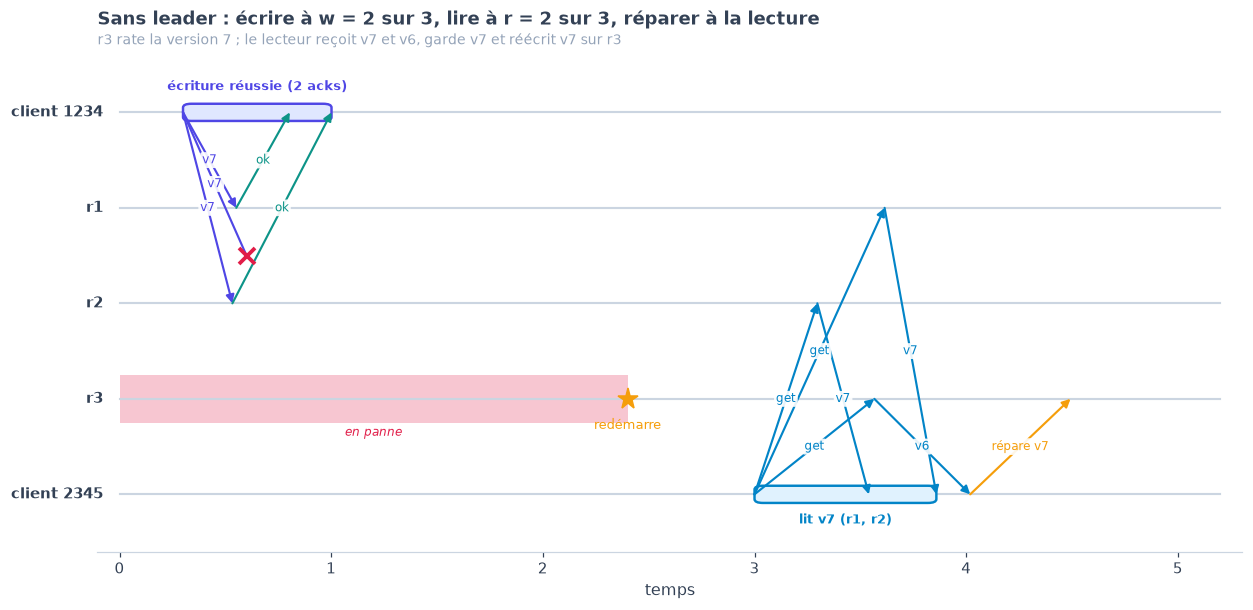

,r1,r2,r3
"(version, valeur) finale","(7, nouvelle)","(7, nouvelle)","(7, nouvelle)"


In [2]:
net, reps, cl = rp.dynamo_cluster(3, 2, 2, latency=(0.2, 0.7), read_repair=True, seed=4,
                                  clients=("client 1234", "client 2345"))
for r_ in reps.values():
    r_.store["photo"] = (6, "ancienne")
net.at(0.0, net.crash, "r3")
net.at(0.3, cl["client 1234"].put, "photo", 7, "nouvelle")
net.at(2.4, net.recover, "r3")
net.at(3.0, cl["client 2345"].get, "photo")
net.run()
colors = {"put": INDIGO, "put_ok": TEAL, "get": SKY, "get_ok": SKY, "repair": AMBER}
def lab(x):
    m = x.msg
    if m[0] == "get_ok":
        return f"v{m[3]}"
    return {"put": "v7", "put_ok": "ok", "get": "get", "repair": "répare v7"}[m[0]]
st = SpaceTime(["client 1234", "r1", "r2", "r3", "client 2345"], t_max=5.2, width=11.5,
               title="Sans leader : écrire à w = 2 sur 3, lire à r = 2 sur 3, réparer à la lecture",
               subtitle="r3 rate la version 7 ; le lecteur reçoit v7 et v6, garde v7 et réécrit v7 sur r3")
st.from_trace(net.trace, color_of=lambda x: colors[x.msg[0]], label_of=lab)
st.span("r3", 0.0, 2.4, "en panne", color=ROSE)
st.event("r3", 2.4, "redémarre", kind="star")
put = [x for x in cl["client 1234"].results if x["type"] == "put"][0]
get = [x for x in cl["client 2345"].results if x["type"] == "get"][0]
st.op("client 1234", put["t0"], put["t1"], "écriture réussie (2 acks)", color=INDIGO)
st.op("client 2345", get["t0"], get["t1"], f"lit v{get['version']} ({', '.join(get['from'])})", color=SKY, above=False)
st.show()
pd.DataFrame({k: [v.store["photo"]] for k, v in reps.items()}, index=["(version, valeur) finale"])

L'écriture réussit avec les acquittements de `r1` et `r2` ; le client ignore simplement que
`r3` l'a ratée. Le lecteur interroge les trois répliques, prend les deux premières réponses,
et garde la version la plus grande, même si elle ne vient que d'une seule réplique. Puis il
remarque qu'une réplique a répondu une version plus ancienne et lui réécrit la bonne : à
la fin, les trois répliques ont la version 7.

> **À retenir.** Sans leader, pas de basculement : on écrit et on lit sur plusieurs
> répliques en parallèle, et les numéros de version désignent la valeur la plus récente.